# Prune, quantize, or both? 2. The dense baselines as real files

Every point on the project's chart has two coordinates, the size of the saved file in bytes and the top-1 accuracy. Before placing any published method there, we need the reference points it will be compared with, which are DeiT-S and DeiT-Ti at full and reduced precision. Notebook 01 computed the INT8 and INT4 sizes with a formula; here each model is saved to disk in each format, read back, checked against what was written, and evaluated from the file.

The quantizer in this notebook is plain round-to-nearest on the weights of the 48 block linears, with the rest of the model in FP16. It is the simplest method that produces a real file, so it marks the floor that the published methods should improve on. Groups of 64 weights for INT4 follow notebook 01 and are provisional until the sensitivity pilot.

In [1]:
import os, json, time
from pathlib import Path

import numpy as np
import torch
import timm
from timm.data import resolve_data_config, create_transform
import matplotlib.pyplot as plt

from deitc.model import BUILDERS, TIMM_NAMES, load_pretrained
from deitc.data import imagenet_v2, by_wnid, WNID_TO_INDEX
from deitc.evaluate import predict, bootstrap_ci
from safetensors.torch import load_file
from deitc.packing import quantize_state_dict, dequantized_state_dict, save_packed, load_packed, save_float

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA = {
    "ImageNet-1k val": Path(os.environ.get("IMAGENET_VAL_DIR", "../data/imagenet/val")),
    "ImageNet-V2": Path(os.environ.get("IMAGENETV2_DIR", "../data/imagenetv2-matched-frequency-format-val")),
    "ImageNet-R": Path(os.environ.get("IMAGENETR_DIR", "../data/imagenet-r")),
}
OUT = Path("outputs"); ART = OUT / "artifacts"; ART.mkdir(parents=True, exist_ok=True)
GROUP = 64
for k, p in DATA.items(): print(f"{k:<16} {'found' if p.exists() else 'missing':<8} {p}")
print("torch", torch.__version__, "| timm", timm.__version__, "|", torch.cuda.get_device_name() if DEVICE == "cuda" else "cpu")

ImageNet-1k val  found    ../data/imagenet/val
ImageNet-V2      found    ../data/imagenetv2-matched-frequency-format-val
ImageNet-R       found    ../data/imagenet-r
torch 2.11.0+cu128 | timm 1.0.30 | NVIDIA GeForce RTX 4070


## 1. Saving each format

FP32 and FP16 are the plain `state_dict` in that precision. INT8 keeps one FP16 scale per output row of each block linear. INT4 keeps an FP16 scale and an FP16 minimum per group, and stores two codes per byte. The size is that of the `safetensors` file, header included. Each file is read back and its dequantized weights must equal, bit for bit, the ones the evaluation would have used without the file.

In [2]:
part1 = {(r["model"], r["format"]): r for r in json.load(open(OUT / "rebuild_summary.json"))["sizes_mb"]} if (OUT / "rebuild_summary.json").exists() else {}

files = {}
for name in ["DeiT-S", "DeiT-Ti"]:
    sd = load_pretrained(name).state_dict()
    for fmt in ["FP32", "FP16", "INT8", "INT4"]:
        path = ART / f"{name.lower()}_{fmt.lower()}.safetensors"
        if fmt.startswith("FP"):
            size = save_float(sd, path, torch.float32 if fmt == "FP32" else torch.float16)
            exact = True
        else:
            bits = int(fmt[3:])
            q = quantize_state_dict(sd, bits, GROUP)
            size = save_packed(q, path, bits, GROUP)
            ref, back = dequantized_state_dict(q, bits, GROUP), load_packed(path)
            exact = set(ref) == set(back) and all(torch.equal(ref[k], back[k]) for k in ref)
        files[(name, fmt)] = path
        acc = part1.get((name, fmt), {}).get("real_or_accounted")
        print(f"{name:<8} {fmt:<5} {size/1e6:8.3f} MB   notebook 01: {acc if acc is None else round(acc, 3)!s:>8} MB   round-trip exact: {exact}")
        assert exact

DeiT-S   FP32    88.216 MB   notebook 01:   88.216 MB   round-trip exact: True
DeiT-S   FP16    44.115 MB   notebook 01:   44.115 MB   round-trip exact: True
DeiT-S   INT8    22.971 MB   notebook 01:   22.951 MB   round-trip exact: True
DeiT-S   INT4    13.603 MB   notebook 01:   13.578 MB   round-trip exact: True


DeiT-Ti  FP32    22.883 MB   notebook 01:   22.883 MB   round-trip exact: True
DeiT-Ti  FP16    11.448 MB   notebook 01:   11.448 MB   round-trip exact: True
DeiT-Ti  INT8     6.188 MB   notebook 01:    6.168 MB   round-trip exact: True
DeiT-Ti  INT4     3.828 MB   notebook 01:    3.804 MB   round-trip exact: True


## 2. Accuracy from the files

Each model is built from its file, with the weights dequantized to FP32, so the activations stay in full precision and only the stored weights change. ImageNet-R covers 200 of the 1 000 classes, and as in Hendrycks et al. (2021) the prediction is taken over those 200 classes only. We keep the per-image results so that later comparisons can be paired.

In [3]:
cfg = resolve_data_config({}, model=timm.create_model(TIMM_NAMES["DeiT-S"], pretrained=False))
tfm = create_transform(**cfg)

models = {}
for (name, fmt), path in files.items():
    m = BUILDERS[name]()
    sd = load_packed(path) if fmt.startswith("INT") else {k: v.float() for k, v in load_file(str(path)).items()}
    m.load_state_dict(sd, strict=True)
    models[f"{name} {fmt}"] = m.eval()

results, correct_by = {}, {}
for dname, root in DATA.items():
    if not root.exists():
        print(f"{dname}: missing, skipped"); continue
    ds = imagenet_v2(root, tfm) if dname == "ImageNet-V2" else by_wnid(root, tfm)
    loader = torch.utils.data.DataLoader(ds, batch_size=250, num_workers=8, pin_memory=True)
    t0 = time.time(); logits, labels = predict(models, loader, DEVICE)
    mask = None
    if dname == "ImageNet-R":
        classes = sorted({WNID_TO_INDEX[p.name] for p in root.iterdir() if p.is_dir()})
        mask = torch.full((1000,), float("-inf")); mask[classes] = 0
    print(f"{dname}: {len(ds)} images, {time.time() - t0:.0f} s")
    for k, lg in logits.items():
        pred = (lg + mask).argmax(1) if mask is not None else lg.argmax(1)
        c = (pred == labels).numpy().astype(float)
        lo, hi = bootstrap_ci(c)
        correct_by[(dname, k)] = c
        results.setdefault(k, {})[dname] = {"top1": c.mean() * 100, "ci95": [lo, hi]}
        print(f"  {k:<14} top-1 {c.mean()*100:6.2f} % [{lo:.2f}, {hi:.2f}]")

ImageNet-1k val: 50000 images, 274 s


  DeiT-S FP32    top-1  79.86 % [79.49, 80.22]


  DeiT-S FP16    top-1  79.86 % [79.49, 80.23]


  DeiT-S INT8    top-1  79.84 % [79.47, 80.20]


  DeiT-S INT4    top-1  79.18 % [78.80, 79.57]


...

  DeiT-S INT4    top-1  41.68 % [41.12, 42.23]


  DeiT-Ti FP32   top-1  32.70 % [32.18, 33.21]


  DeiT-Ti FP16   top-1  32.70 % [32.17, 33.21]


  DeiT-Ti INT8   top-1  32.84 % [32.31, 33.35]


  DeiT-Ti INT4   top-1  31.53 % [30.99, 32.04]


## 3. Paired differences against FP32

With the same images under both models, the difference in accuracy has a much narrower interval than either accuracy alone. We resample images, recompute the difference each time, and report the 95 % interval.

In [4]:
def paired_diff_ci(a, b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n_boot, len(a)))
    d = (a[idx] - b[idx]).mean(1) * 100
    return (a.mean() - b.mean()) * 100, np.percentile(d, [2.5, 97.5])

paired = {}
for (dname, k), c in correct_by.items():
    name, fmt = k.split()
    if fmt == "FP32": continue
    diff, (lo, hi) = paired_diff_ci(c, correct_by[(dname, f"{name} FP32")])
    paired.setdefault(k, {})[dname] = {"diff": diff, "ci95": [lo, hi]}
    print(f"{dname:<16} {k:<14} vs FP32: {diff:+6.2f} points [{lo:+.2f}, {hi:+.2f}]")

ImageNet-1k val  DeiT-S FP16    vs FP32:  +0.00 points [-0.01, +0.01]


ImageNet-1k val  DeiT-S INT8    vs FP32:  -0.02 points [-0.07, +0.03]


ImageNet-1k val  DeiT-S INT4    vs FP32:  -0.67 points [-0.84, -0.52]


ImageNet-1k val  DeiT-Ti FP16   vs FP32:  +0.01 points [-0.01, +0.02]


ImageNet-1k val  DeiT-Ti INT8   vs FP32:  -0.02 points [-0.08, +0.04]


...

ImageNet-R       DeiT-S INT8    vs FP32:  +0.03 points [-0.04, +0.11]


ImageNet-R       DeiT-S INT4    vs FP32:  -0.56 points [-0.80, -0.30]


ImageNet-R       DeiT-Ti FP16   vs FP32:  -0.00 points [-0.02, +0.01]


ImageNet-R       DeiT-Ti INT8   vs FP32:  +0.14 points [+0.06, +0.22]


ImageNet-R       DeiT-Ti INT4   vs FP32:  -1.17 points [-1.44, -0.91]


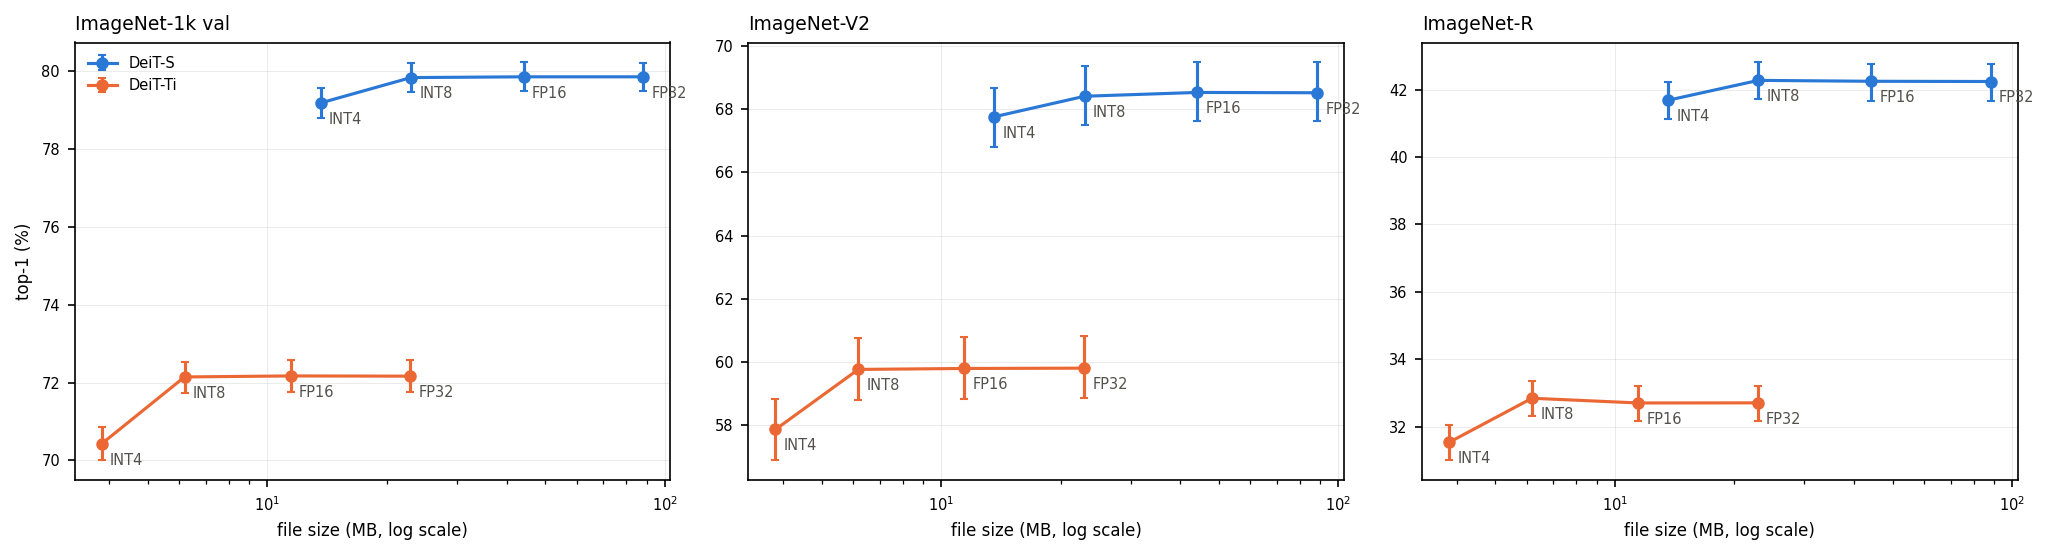

In [5]:
sizes = {f"{n} {f}": p.stat().st_size / 1e6 for (n, f), p in files.items()}
dsets = [d for d in DATA if any(d in r for r in results.values())]
C = {"DeiT-S": "#2a78d6", "DeiT-Ti": "#eb6834"}
fig, axes = plt.subplots(1, len(dsets), figsize=(4.6 * len(dsets), 3.8), dpi=150, squeeze=False)
for ax, d in zip(axes[0], dsets):
    for name in ["DeiT-S", "DeiT-Ti"]:
        ks = [f"{name} {f}" for f in ["INT4", "INT8", "FP16", "FP32"]]
        x = [sizes[k] for k in ks]; y = [results[k][d]["top1"] for k in ks]
        err = np.array([[results[k][d]["top1"] - results[k][d]["ci95"][0], results[k][d]["ci95"][1] - results[k][d]["top1"]] for k in ks]).T
        ax.errorbar(x, y, yerr=err, color=C[name], marker="o", ms=5, lw=1.5, capsize=2, label=name)
        for k, xi, yi in zip(ks, x, y): ax.annotate(k.split()[1], (xi, yi), textcoords="offset points", xytext=(4, -10), fontsize=7, color="#52514e")
    ax.set_xscale("log"); ax.set_xlabel("file size (MB, log scale)", fontsize=8); ax.set_title(d, fontsize=9, loc="left")
    ax.tick_params(labelsize=7); ax.grid(alpha=0.25, lw=0.5)
axes[0][0].set_ylabel("top-1 (%)", fontsize=8); axes[0][0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_baselines.png", bbox_inches="tight"); plt.show()

## 4. What we see

The packed files land within 0.03 MB of the sizes notebook 01 computed, the difference being the file header and the names of the stored tensors, so the real file now replaces the formula. At full precision our pipeline gives 79.86 % for DeiT-S and 72.17 % for DeiT-Ti on ImageNet-1k val, in line with the 79.8 % and 72.2 % reported by Touvron et al. (2021).

FP16 and INT8 cost nothing that matters for either model, since every paired difference against FP32 stays within 0.15 points on the three test sets. INT4 with plain rounding is where accuracy starts to fall. On ImageNet-1k val DeiT-S loses 0.7 points and DeiT-Ti 1.7, and the smaller model loses more on all three sets.

The comparison that matters for the chart runs across models. DeiT-S at INT4 takes 13.6 MB and DeiT-Ti at FP16 takes 11.4 MB, so the small dense model is still 2.2 MB lighter, but DeiT-S at INT4 is 7 points more accurate on ImageNet-1k val, 8 on ImageNet-V2 and 9 on ImageNet-R. Below 13.6 MB, DeiT-S needs fewer than four bits per weight or fewer weights, and that is the range where the published methods and our mix have to be compared with DeiT-Ti at INT8 (6.2 MB) and INT4 (3.8 MB).

In [6]:
summary = {"group": GROUP, "quantizer": "round-to-nearest, weights of the 48 block linears; rest FP16",
           "size_mb": sizes, "accuracy": results, "paired_vs_fp32": paired}
with open(OUT / "baselines_summary.json", "w") as f: json.dump(summary, f, indent=2, default=float)
np.savez_compressed(OUT / "baselines_per_image.npz", **{f"{d}|{k}": c.astype(np.uint8) for (d, k), c in correct_by.items()})
print("saved", OUT / "baselines_summary.json")

saved outputs/baselines_summary.json


### References

- Hendrycks, D., et al. (2021). The many faces of robustness: A critical analysis of out-of-distribution generalization. *ICCV*.
- Recht, B., Roelofs, R., Schmidt, L., & Shankar, V. (2019). Do ImageNet classifiers generalize to ImageNet? *ICML*.
- Touvron, H., et al. (2021). Training data-efficient image transformers & distillation through attention. *ICML*.